# Ejercicio Ridge, Lasso y ElasticNet
Para este ejercicio vas a trabajar con datos de ventas de una empresa que fabrica muebles en España. Esta empresa es una Pyme que demanda conocer de antemano qué ingresos va a tener cada mes, ya que necesita pedir un anticipio a su entidad financiera de cara a poder abastecerse de materia prima al comenzar el mes. Como desconoce cuánto tiene que pedir, tira al alza y acaba pagando muchos intereses. El objetivo es reducir estos gastos.

En las bases de datos de la empresa constan todos los gastos en publicidad y ventas, para cada uno de los meses desde su fundación (hace más de 15 años).

Dado que los presupuestos de marketing se cierran al principio de cada mes, la empresa necesita un modelo predictivo que le anticipe las ventas que conseguirá a final de mes en función de los gastos que realizará en marketing.

Para ello tendrás que utilizar tanto modelos de regresión normales, como regularizados.

1. Carga los datos y realiza un pequeño análisis exploratorio. Mira a ver cómo se relaciona las ventas con el resto de variables.
2. Crea varios modelos y modifica los hiperparámetros necesarios para mejorar el performance del modelo.
3. Interpreta los resultados. Traduce a una fórmula tu mejor modelo (escribir la fórmula simplemente). ¿Cuánto cambian las ventas si aumentamos la inversión en radio un punto más? ¿Y si aumentamos la inversión en TV o periódicos?

## Import libraries 

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.preprocessing import PolynomialFeatures, StandardScaler, MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

## Exploratory Data Analysis 

In [3]:
df = pd.read_csv(
    "data/advertising.csv",
    index_col=0
)

df = df.rename(columns={"newpaper": "newspaper"})
df["newspaper"] = pd.to_numeric(
    df["newspaper"].replace({"6s9.2": "69.2"})
)

display(df.head())
display(df.describe())

,TV,radio,newspaper,sales
0,230.1,37.8,69.2,22100.0
1,44.5,39.3,45.1,10400.0
2,17.2,45.9,69.3,9300.0
3,151.5,41.3,58.5,18500.0
4,180.8,10.8,58.4,12900.0


,TV,radio,newspaper,sales
count,200.000000,200.000000,200.000000,200.000000
mean,147.042500,23.264000,30.554000,14022.500000
std,85.854236,14.846809,21.778621,5217.456566
min,0.700000,0.000000,0.300000,1600.000000
25%,74.375000,9.975000,12.750000,10375.000000
50%,149.750000,22.900000,25.750000,12900.000000
75%,218.825000,36.525000,45.100000,17400.000000
max,296.400000,49.600000,114.000000,27000.000000


<Axes: >

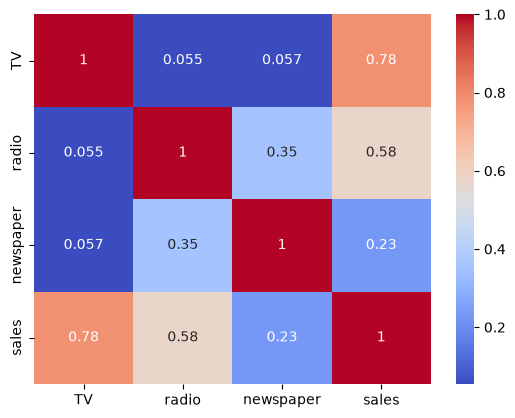

In [4]:
sns.heatmap(
    df.corr(),
    annot=True,
    cmap="coolwarm",
    
)


TV           0.782224
radio        0.576223
newspaper    0.228299
sales        1.000000
Name: sales, dtype: float64


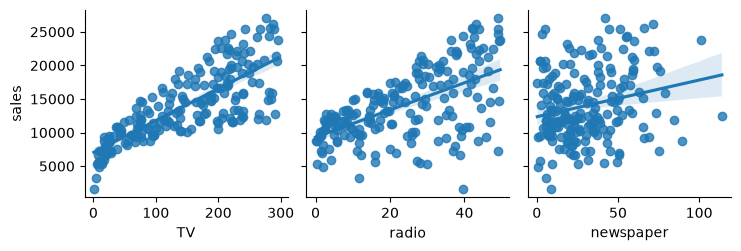

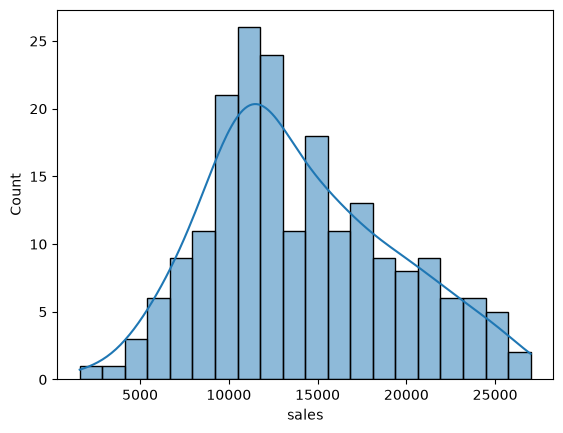

In [5]:
# Correlaciones entre variables
print(df.corr(numeric_only=True)["sales"])

# Ventas frente a cada inversión
sns.pairplot(
    df,
    x_vars=["TV", "radio", "newspaper"],
    y_vars=["sales"],
    kind="reg"
)
plt.show()

# Distribución de las ventas
sns.histplot(df["sales"], bins=20, kde=True)
plt.show()

## Modelado

In [6]:
from sklearn.model_selection import train_test_split

X = df[["TV", "radio", "newspaper"]]
y = df["sales"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [7]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

modelo = LinearRegression()
modelo.fit(X_train, y_train)

predicciones = modelo.predict(X_test)

print("RMSE:", mean_squared_error(y_test, predicciones) ** 0.5)
print("R²:", r2_score(y_test, predicciones))

RMSE: 1781.5996615334504
R²: 0.899438024100912


Lo de arriba RMSE: 1.781,6: en el conjunto de prueba, las predicciones se desvían de las ventas reales unas 1.782 unidades de ventas de media. No es el error máximo. 
R²: 0,899 ≈ 89,9 %: el modelo explica alrededor del 89,9 % de las variaciones de ventas en esos datos. No significa que acierte el 89,9 % de las predicciones.

In [8]:
from sklearn.preprocessing import StandardScaler

escalador = StandardScaler()
X_train_scaled = escalador.fit_transform(X_train)
X_test_scaled = escalador.transform(X_test)

In [9]:
from sklearn.linear_model import Ridge

modelo_ridge = Ridge(alpha=1)
modelo_ridge.fit(X_train_scaled, y_train)

predicciones = modelo_ridge.predict(X_test_scaled)
print("RMSE Ridge:", mean_squared_error(y_test, predicciones) ** 0.5)

RMSE Ridge: 1787.2201577332223


El modelo Ridge suele fallar por unas 1.787 unidades de ventas al predecir. P ej.: si las ventas son 10.000, podría predecir cerca de 8.213. 
Para recordar: Ridge los hace más pequeños, pero normalmente mantiene todas las variables.

In [10]:
from sklearn.preprocessing import StandardScaler

X_scaled = StandardScaler().fit_transform(X_train)
alphas = np.logspace(-3, 3, 100)

coef_ridge = []
coef_lasso = []

for a in alphas:
    coef_ridge.append(Ridge(alpha=a).fit(X_scaled, y_train).coef_)
    coef_lasso.append(
        Lasso(alpha=a, max_iter=10000).fit(X_scaled, y_train).coef_
    )

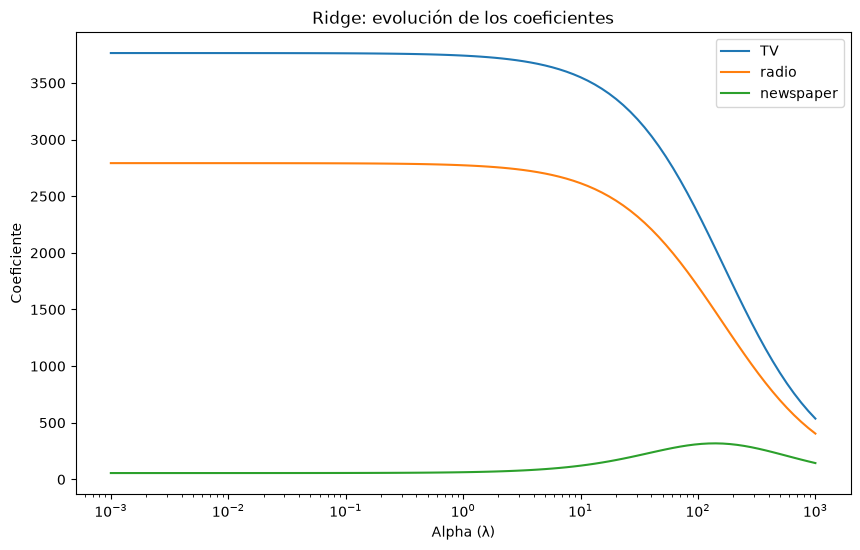

In [11]:
plt.figure(figsize=(10, 6))
plt.plot(alphas, coef_ridge)
plt.xscale("log")
plt.xlabel("Alpha (λ)")
plt.ylabel("Coeficiente")
plt.title("Ridge: evolución de los coeficientes")
plt.legend(X_train.columns)
plt.show()

In [12]:
from sklearn.linear_model import Lasso

modelo_lasso = Lasso(alpha=1, max_iter=10000)
modelo_lasso.fit(X_train_scaled, y_train)

predicciones = modelo_lasso.predict(X_test_scaled)
print("RMSE Lasso:", mean_squared_error(y_test, predicciones) ** 0.5)   #para calcular la raiz cuadrada ** 0.5

'''la linea anterior puede ser asi tambien: 
import numpy as np
np.sqrt(mean_squared_error(y_test, predicciones))'''



RMSE Lasso: 1781.5871507029278


'la linea anterior puede ser asi tambien: \nimport numpy as np\nnp.sqrt(mean_squared_error(y_test, predicciones))'

Comparado con Ridge (RMSE ≈ 1.787), Lasso tiene un error apenas menor. En esta prueba, los resultados son prácticamente iguales. 
Para recordar: Lasso también los reduce, pero puede dejar alguno en cero, eliminando así variables poco útiles.

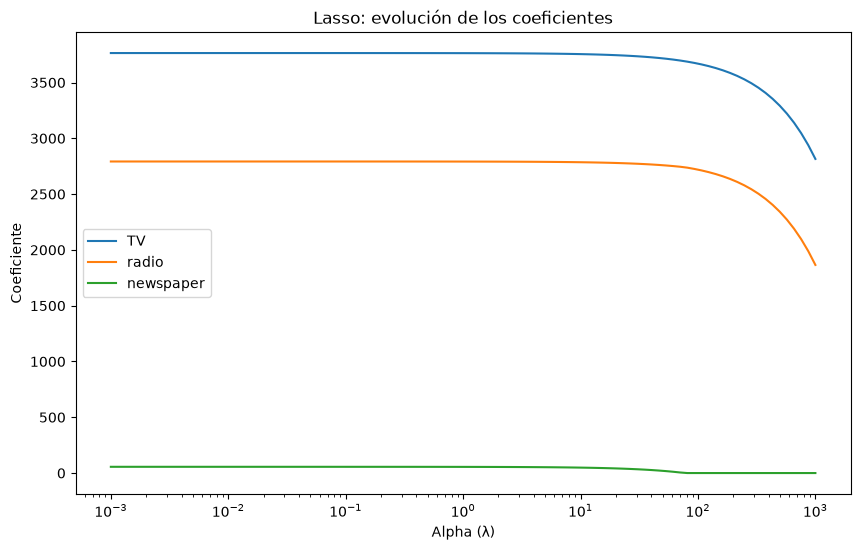

In [13]:
plt.figure(figsize=(10, 6))
plt.plot(alphas, coef_lasso)
plt.xscale("log")
plt.xlabel("Alpha (λ)")
plt.ylabel("Coeficiente")
plt.title("Lasso: evolución de los coeficientes")
plt.legend(X_train.columns)
plt.show()

In [14]:
from sklearn.linear_model import ElasticNet

modelo_elastic = ElasticNet(alpha=1, max_iter=10000)
modelo_elastic.fit(X_train_scaled, y_train)

predicciones = modelo_elastic.predict(X_test_scaled)
print("RMSE ElasticNet:", mean_squared_error(y_test, predicciones) ** 0.5)

RMSE ElasticNet: 2599.2665199408316


Las predicciones se equivocan más que las de Ridge y Lasso en esta prueba, así que con los parámetros actuales, ElasticNet funciona peor.

#### Regresión lineal, Ridge y Lasso (Gráfico integrado)

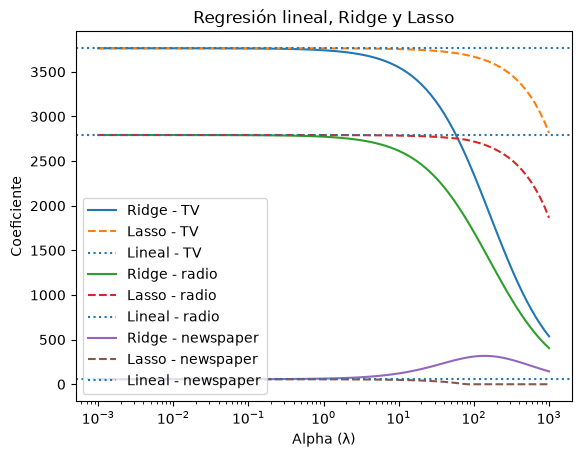

In [15]:

ridge_coefs = np.array(coef_ridge)
lasso_coefs = np.array(coef_lasso)
linear_coefs = LinearRegression().fit(X_scaled, y_train).coef_

for i, variable in enumerate(X_train.columns):
    plt.plot(alphas, ridge_coefs[:, i], label=f"Ridge - {variable}")
    plt.plot(alphas, lasso_coefs[:, i], "--", label=f"Lasso - {variable}")
    plt.axhline(linear_coefs[i], linestyle=":", label=f"Lineal - {variable}")

plt.xscale("log")
plt.xlabel("Alpha (λ)")
plt.ylabel("Coeficiente")
plt.title("Regresión lineal, Ridge y Lasso")
plt.legend()
plt.show()

Explicación:

El gráfico muestra cómo cambia el peso de cada inversión publicitaria en el modelo al aumentar la regularización (alpha). Las líneas punteadas son la regresión lineal sin regularización. Las líneas continuas (Ridge) y discontinuas (Lasso) muestran cómo esos coeficientes se reducen al penalizar el modelo. En esta gráfica, el coeficiente de periódicos con Lasso se acerca a cero, mientras que los de TV y radio siguen siendo positivos. Esto sugiere que, para este modelo, TV y radio aportan más información para predecir las ventas que periódicos.


### Modelos Polinómicos

In [16]:
from sklearn.preprocessing import PolynomialFeatures

polinomio = PolynomialFeatures(degree=2, include_bias=False)

X_train_poly = polinomio.fit_transform(X_train)
X_test_poly = polinomio.transform(X_test)

modelo_poly = LinearRegression()
modelo_poly.fit(X_train_poly, y_train)

predicciones = modelo_poly.predict(X_test_poly)

print("RMSE polinómico:", mean_squared_error(y_test, predicciones) ** 0.5)
print("R² polinómico:", r2_score(y_test, predicciones))

RMSE polinómico: 642.5809120553573
R² polinómico: 0.9869181490609606


Text(0.5, 1.0, 'Error de predicción por modelo')

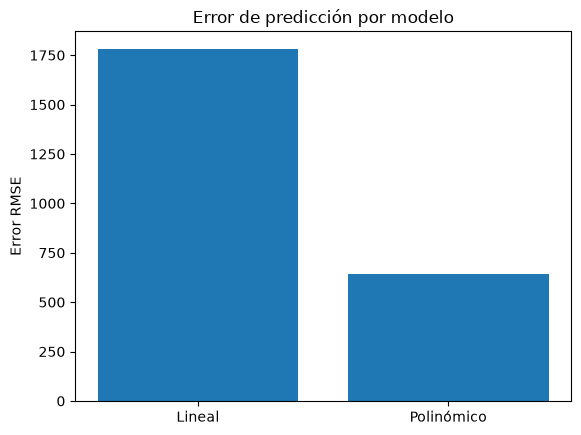

In [ ]:

error_lineal = mean_squared_error(
    y_test, modelo.predict(X_test)
) ** 0.5

error_polinomico = mean_squared_error(
    y_test, modelo_poly.predict(X_test_poly)
) ** 0.5

plt.bar(
    ["Lineal", "Polinómico"],
    [error_lineal, error_polinomico]
)
plt.ylabel("Error RMSE")
plt.title("Error de predicción por modelo")



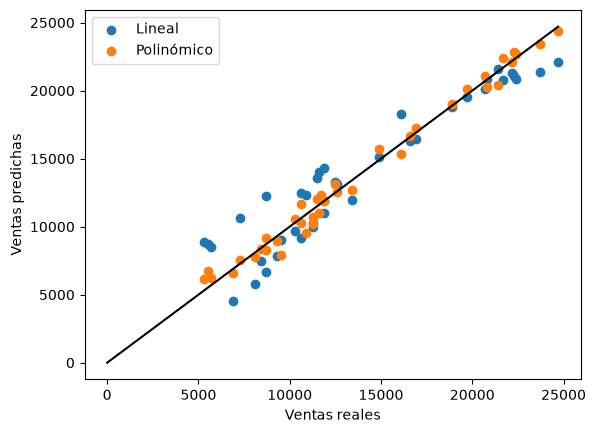

In [ ]:
pred_lineal = modelo.predict(X_test)
pred_polinomico = modelo_poly.predict(X_test_poly)

plt.scatter(y_test, pred_lineal, label="Lineal")
plt.scatter(y_test, pred_polinomico, label="Polinómico")

# Recta de predicción perfecta
limite = max(y_test.max(), pred_lineal.max(), pred_polinomico.max())
plt.plot([0, limite], [0, limite], color="black")

plt.xlabel("Ventas reales")
plt.ylabel("Ventas predichas")
plt.legend()


## Resultados

La regresión lineal tuvo un RMSE de prueba de aproximadamente 1.782. Ridge obtuvo 1.787, Lasso 1.782 y ElasticNet 2.599. Por tanto, con estos parámetros, la regresión lineal y Lasso dieron resultados casi iguales; ElasticNet tuvo más error.

La regresión polinómica de grado 2 obtuvo un RMSE cercano a 643, menor que el lineal. En esta prueba, sus predicciones fueron más precisas.

Para interpretar las métricas: RMSE más bajo significa menos error y R² más cercano a 1 significa que el modelo explica mejor las ventas.

### Extra solo para mí

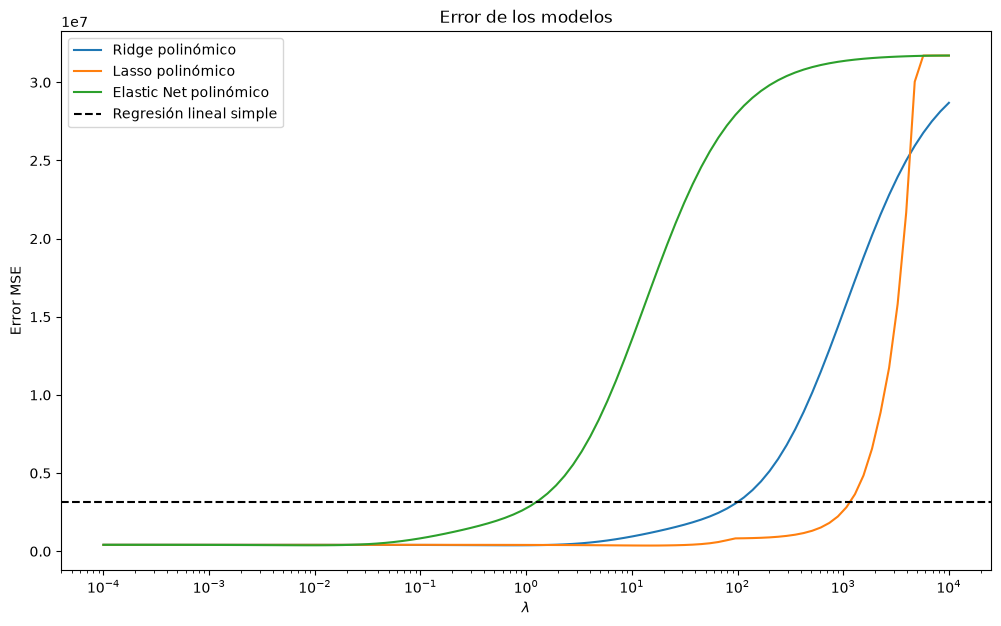

In [21]:
from sklearn.pipeline import make_pipeline


alphas = np.logspace(-4, 4, 100)
errores = {"Ridge polinómico": [], "Lasso polinómico": [], "Elastic Net polinómico": []}

for alpha in alphas:
    modelos = {
        "Ridge polinómico": Ridge(alpha=alpha),
        "Lasso polinómico": Lasso(alpha=alpha, max_iter=10000),
        "Elastic Net polinómico": ElasticNet(alpha=alpha, l1_ratio=0.5, max_iter=10000)
    }

    for nombre, modelo in modelos.items():
        pipeline = make_pipeline(
            PolynomialFeatures(degree=2, include_bias=False),
            StandardScaler(),
            modelo
        )
        pipeline.fit(X_train, y_train)
        errores[nombre].append(
            mean_squared_error(y_test, pipeline.predict(X_test))
        )

lineal = LinearRegression().fit(X_train, y_train)
error_lineal = mean_squared_error(y_test, lineal.predict(X_test))

plt.figure(figsize=(12, 7))
for nombre, valores in errores.items():
    plt.plot(alphas, valores, label=nombre)

plt.axhline(error_lineal, color="black", linestyle="--",
            label="Regresión lineal simple")
plt.xscale("log")
plt.xlabel(r"$\lambda$")
plt.ylabel("Error MSE")
plt.title("Error de los modelos")
plt.legend()
plt.show()